# Exploratory Visual Analysis: Renewable Energy and National Income
**Dataset:** World Bank, World Development Indicators (`WDICSV.csv`)

**Final question:** Is the negative relationship between national income and renewable energy share driven by
traditional biomass rather than by modern renewables (wind, solar)? And does income predict modern renewable adoption at all?

This notebook reproduces the numbers and Figures 2–7 in the write-up. Figure numbers here match the write-up.

| Section | Contents | Figure | Saved as |
|---|---|---|---|
| 1. Setup | Parameters, plot style, color palette | | |
| 2. Load data | Raw wide table, split into economies vs. aggregates | | |
| 3. Data profile | Size, completeness, anomaly check, coverage by year | **Figure 2** | `f2_coverage.png` |
| 4. Build analysis table | One row per economy for `YEAR`; correlations; income-band medians | | |
| 5. Iterations | Income-group bars, trends, country scatter, non-hydro trends | **Figures 3–6** | `f3_bar_income.png`, `f4_ts_income.png`, `f5_scatter_total.png`, `f6_ts_nonhydro.png` |
| 6. Final visualization | Biomass vs. modern renewables, small multiples | **Figure 7** | `f7_final.png` |

**To run:** put `WDICSV.csv` next to this notebook (or edit `DATA_PATH`), then *Run All*. Loading the 199 MB CSV takes ~20–40 s.
Requires `pandas`, `numpy`, `matplotlib` (see `requirements.txt`). Figures are saved to `figures/`.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

# ---- Parameters you may want to change -------------------------------------
DATA_PATH = Path("WDICSV.csv")   # path to the World Bank CSV
FIG_DIR   = Path("figures")       # where PNGs are saved
SAVE_FIGS = True                  # set False to only display
YEAR      = "2021"                # cross-section year (latest year with full renewable coverage)
# -----------------------------------------------------------------------------
FIG_DIR.mkdir(exist_ok=True)

# Palette: text/grid neutrals, categorical accents, and an ordinal blue ramp for income groups
TXT, TXT2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
RAMP  = {"LIC": "#86b6ef", "LMC": "#3987e5", "UMC": "#1c5cab", "HIC": "#0d366b"}   # light -> dark = poor -> rich
NAMES = {"LIC": "Low income", "LMC": "Lower-middle income",
         "UMC": "Upper-middle income", "HIC": "High income"}
GROUPS = ["LIC", "LMC", "UMC", "HIC"]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": TXT2,
    "xtick.color": TXT2, "ytick.color": TXT2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TXT,
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "legend.frameon": False,
})

pct = FuncFormatter(lambda v, _: f"{v:.0f}%")
usd = FuncFormatter(lambda v, _: f"${v/1000:.0f}k" if v >= 1000 else f"${v:.0f}")

def note(fig, text, y=-0.02):
    # Source / method note under a figure
    fig.text(0.0, y, text, fontsize=8, color=TXT2, ha="left", va="top")

def save(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / name)
    plt.show()

## 2. Load data
The file is *wide*: one row per entity × indicator, one column per year (1960–2025). The 49 aggregates (regions, income groups, World) are mixed in with the 217 economies, so they are separated explicitly.

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")          # utf-8-sig strips the BOM on the first header
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]       # drop trailing empty column if present
YEARS = [c for c in df.columns if c.isdigit()]

AGGREGATES = ['AFE','AFW','ARB','CSS','CEB','EAR','EAS','EAP','TEA','EMU','ECS','ECA','TEC','EUU','FCV',
              'HPC','HIC','IBD','IBT','IDB','IDX','IDA','LTE','LCN','LAC','TLA','LDC','LMY','LIC','LMC',
              'MEA','MNA','TMN','MIC','NAC','INX','OED','OSS','PSS','PST','PRE','SST','SAS','TSA','SSF',
              'SSA','TSS','UMC','WLD']
is_agg = df["Country Code"].isin(AGGREGATES)
countries = df[~is_agg]
names = df[["Country Code", "Country Name"]].drop_duplicates().set_index("Country Code")["Country Name"]

def short(code):
    # Display name for chart labels
    return names[code].replace(", Dem. Rep.", " (DRC)")

def series(code, entities=None, countries_only=False):
    # Rows of one indicator, indexed by country code, columns = years
    s = df[df["Indicator Code"] == code].set_index("Country Code")[YEARS]
    if countries_only:
        s = s[~s.index.isin(AGGREGATES)]
    return s.loc[entities] if entities is not None else s

df.head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,18.471500,18.822373,19.302882,19.770426,20.120927,20.440680,20.817895,21.161010,21.532841,NaN
1,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,7.682625,7.953281,8.528101,8.878267,9.050266,9.111884,9.285654,9.403676,9.687390,NaN
2,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,39.163151,39.206303,39.406216,39.569413,39.958115,40.025590,40.203585,40.728295,41.118943,NaN


## 3. Data profile
Overall size and completeness of the file, a check for impossible values, and data coverage by year.

In [3]:
n_cells = df[YEARS].size
print(f"File size:          {DATA_PATH.stat().st_size/1e6:,.1f} MB")
print(f"Shape:              {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Entities:           {df['Country Code'].nunique()} ({countries['Country Code'].nunique()} economies + {is_agg.groupby(df['Country Code']).first().sum()} aggregates)")
print(f"Indicators:         {df['Indicator Code'].nunique():,}")
print(f"Years:              {YEARS[0]}-{YEARS[-1]} ({len(YEARS)} columns)")
print(f"Value cells:        {n_cells:,}; non-missing {df[YEARS].notna().sum().sum():,} ({df[YEARS].notna().mean().mean():.1%})")

ind_cov = countries.groupby("Indicator Code")[YEARS].apply(lambda x: x.notna().mean().mean())
print(f"Indicators <1% filled: {(ind_cov < 0.01).sum()}   |   completely empty: {(ind_cov == 0).sum()}")

print("\nSparsest economies (non-missing cells):")
print(countries.groupby("Country Name")[YEARS].apply(lambda x: x.notna().sum().sum()).sort_values().head(6).to_string())

File size:          198.9 MB
Shape:              398,468 rows x 70 columns
Entities:           266 (217 economies + 49 aggregates)
Indicators:         1,498
Years:              1960-2025 (66 columns)
Value cells:        26,298,888; non-missing 9,045,734 (34.4%)


Indicators <1% filled: 81   |   completely empty: 1

Sparsest economies (non-missing cells):
Country Name
St. Martin (French part)      6264
Isle of Man                   8412
Channel Islands               8615
Sint Maarten (Dutch part)     8918
Northern Mariana Islands      9549
Curacao                      10479


### Anomaly check
Percentage shares should be between 0% and 100%. The non-hydro renewable electricity share has negative values, which are reporting artifacts.
They are left visible in Figure 6 and clipped to 0 in Figure 7.

In [4]:
# Anomaly check: percentage-share indicators should never be negative
share = series("EG.ELC.RNWX.ZS")
neg = share.stack()[lambda s: s < 0]
print(f"Negative values in 'non-hydro renewable electricity (% of total)': {len(neg)}")
print(neg.sort_values().head(10).rename(index=names, level=0).round(1).to_string())

Negative values in 'non-hydro renewable electricity (% of total)': 628
Country Code      
Congo, Rep.   2000   -71.1
Luxembourg    1998   -69.6
              1997   -66.2
              1996   -63.8
              1999   -61.2
              1995   -58.9
              1990   -53.7
              1991   -49.5
              1994   -48.4
              1992   -43.9


### Coverage by year (Figure 2)
Share of economy × indicator cells with a value, by year. Coverage is thin before 1990, peaks at 59% in 2015, and drops in the latest years
because they haven't been reported yet. Renewable energy indicators end in 2021, so 2021 is used for the cross-section.

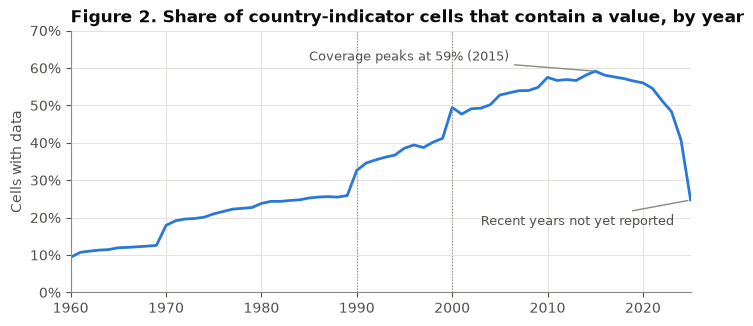

In [5]:
# Figure 2: data coverage by year
cov = countries[YEARS].notna().mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot([int(y) for y in YEARS], cov.values, color=BLUE, lw=2)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 70); ax.set_xlim(int(YEARS[0]), int(YEARS[-1]))
ax.set_title("Figure 2. Share of country-indicator cells that contain a value, by year")
ax.set_ylabel("Cells with data")
for y in [1990, 2000]:
    ax.axvline(y, color=MUTED, lw=0.8, ls=":")
ax.annotate(f"Coverage peaks at {cov.max():.0f}% ({cov.idxmax()})", (int(cov.idxmax()), cov.max()), (1985, 62),
            fontsize=9, color=TXT2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.annotate("Recent years not yet reported", (int(YEARS[-1]), cov.iloc[-1]), (2003, 18),
            fontsize=9, color=TXT2, arrowprops=dict(arrowstyle="-", color=MUTED))
save(fig, "f2_coverage.png")

## 4. Build the analysis table
One row per economy for `YEAR`, one column per indicator. Codes are listed in `INDICATORS` so you can swap in others.
The cell prints how many economies report each indicator, then each energy measure's correlation with log₁₀ GDP per capita.

In [6]:
INDICATORS = {
    "ren":  "EG.FEC.RNEW.ZS",     # Renewable energy consumption (% of total final energy)
    "crnw": "EG.USE.CRNW.ZS",     # Combustible renewables and waste (% of total energy) -> biomass proxy
    "rnwx": "EG.ELC.RNWX.ZS",     # Electricity from renewables excl. hydro (% of total) -> wind/solar proxy
    "relc": "EG.ELC.RNEW.ZS",     # Renewable electricity output (% of total)
    "hyd":  "EG.ELC.HYRO.ZS",     # Electricity from hydro (% of total)
    "gdp":  "NY.GDP.PCAP.PP.KD",  # GDP per capita, PPP (constant 2021 international $)
    "pop":  "SP.POP.TOTL",        # Population
}
d = pd.DataFrame({k: series(v, countries_only=True)[YEAR] for k, v in INDICATORS.items()})
print("Countries with data in", YEAR); print(d.notna().sum().to_string())

# Correlation of each energy measure with log10(GDP per capita)
d["log_gdp"] = np.log10(d["gdp"])
for k in ["ren", "crnw", "rnwx", "relc", "hyd"]:
    x = d[["log_gdp", k]].dropna()
    print(f"{k:5s} n={len(x):3d}  Pearson r={x.corr().iloc[0,1]:+.2f}  Spearman={x.corr('spearman').iloc[0,1]:+.2f}")

Countries with data in 2021
ren     212
crnw    143
rnwx    208
relc    204
hyd     208
gdp     199
pop     217
ren   n=197  Pearson r=-0.62  Spearman=-0.55
crnw  n=137  Pearson r=-0.71  Spearman=-0.53
rnwx  n=196  Pearson r=+0.25  Spearman=+0.24
relc  n=192  Pearson r=-0.16  Spearman=-0.13
hyd   n=196  Pearson r=-0.27  Spearman=-0.21


Medians of each measure within fixed GDP-per-capita bands (PPP $). These are the medians plotted in Figure 7.

In [7]:
# Medians within fixed income bands (PPP $) - used in Figure 7
BINS = [0, 2500, 5000, 10000, 20000, 40000, 200000]
def band_medians(col):
    x = d[["gdp", col]].dropna().copy()
    x[col] = x[col].clip(lower=0)                     # negative shares are reporting artifacts
    x["band"] = pd.cut(x["gdp"], BINS)
    return x.groupby("band", observed=True).agg(gdp_median=("gdp", "median"),
                                                 value_median=(col, "median"), n=(col, "size"))
pd.concat({k: band_medians(k) for k in ["ren", "crnw", "rnwx"]}, axis=1).round(1)

ren                        crnw                   \
                gdp_median value_median   n gdp_median value_median   n   
band                                                                      
(0, 2500]           1577.4         79.6  13     1582.6         78.4   6   
(2500, 5000]        3456.7         68.9  26     3478.7         73.2  14   
(5000, 10000]       6688.2         35.4  30     7280.1         33.7  20   
(10000, 20000]     15345.6         11.6  44    15285.8          7.2  33   
(20000, 40000]     29431.9         13.2  37    29627.4          8.8  28   
(40000, 200000]    59332.2         12.3  47    57661.3          7.0  36   

                      rnwx                   
                gdp_median value_median   n  
band                                         
(0, 2500]           1577.4          5.7  13  
(2500, 5000]        3456.7          3.5  26  
(5000, 10000]       6688.2         12.7  30  
(10000, 20000]     15290.3          2.5  45  
(20000, 40000]     29431.9          9.1  37  
(40000, 200000]    58327.4         12.6  45

## 5. Iterations
### Iteration 1: Overview by income group (Figure 3)
Hypothesis: richer countries use more renewable energy. Income groups are ordinal, so they get a light→dark single-hue ramp.
Uses the latest year that all four income groups report.

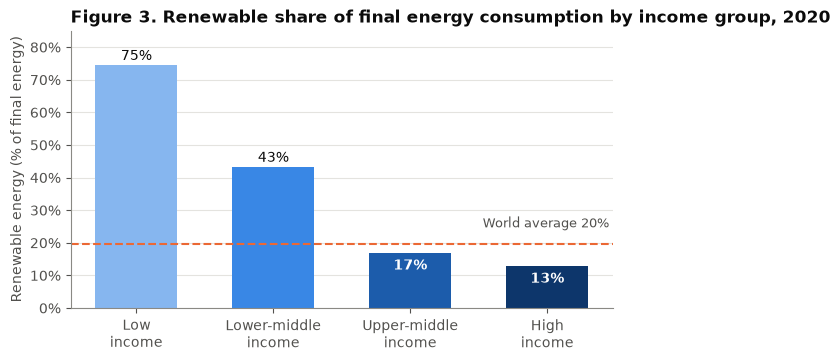

In [8]:
v = series("EG.FEC.RNEW.ZS", GROUPS)
last = [y for y in YEARS if v[y].notna().all()][-1]      # latest year reported for all groups (2020)
v = v[last]; w = series("EG.FEC.RNEW.ZS", "WLD")[last]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar([NAMES[g].replace(" income", "\nincome") for g in GROUPS], v.values,
              color=[RAMP[g] for g in GROUPS], width=0.6)
for r, val in zip(bars, v.values):
    inside = val < 25
    ax.text(r.get_x() + r.get_width()/2, val - 5 if inside else val + 1.5, f"{val:.0f}%", ha="center",
            color="white" if inside else TXT, fontsize=10, fontweight="bold" if inside else "normal")
ax.axhline(w, color=ORANGE, lw=1.5, ls="--")
ax.text(3.45, w + 5, f"World average {w:.0f}%", ha="right", color=TXT2, fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 85); ax.grid(axis="x", visible=False)
ax.set_title(f"Figure 3. Renewable share of final energy consumption by income group, {last}")
ax.set_ylabel("Renewable energy (% of final energy)")
save(fig, "f3_bar_income.png")

### Iteration 2: Change over time (Figure 4)
Is the gap between income groups closing? Labels at the line ends replace a legend.

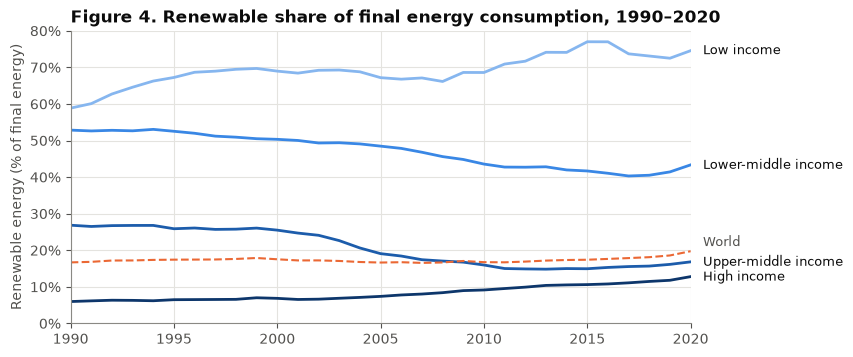

In [9]:
yrs = [str(y) for y in range(1990, int(last) + 1)]
fig, ax = plt.subplots(figsize=(8, 3.8))
for g in GROUPS:
    s = series("EG.FEC.RNEW.ZS", g)[yrs]
    ax.plot([int(y) for y in yrs], s.values, color=RAMP[g], lw=2)
    ax.text(int(last) + 0.6, s[last], NAMES[g], va="center", fontsize=9, color=TXT)
s = series("EG.FEC.RNEW.ZS", "WLD")[yrs]
ax.plot([int(y) for y in yrs], s.values, color=ORANGE, lw=1.5, ls="--")
ax.text(int(last) + 0.6, s[last] + 2.5, "World", va="center", fontsize=9, color=TXT2)
ax.yaxis.set_major_formatter(pct); ax.set_xlim(1990, int(last)); ax.set_ylim(0, 80)
ax.set_title(f"Figure 4. Renewable share of final energy consumption, 1990–{last}")
ax.set_ylabel("Renewable energy (% of final energy)")
save(fig, "f4_ts_income.png")

### Iteration 3: Country-level scatter (Figure 5)
Disaggregate to countries to avoid the ecological fallacy. The x-axis is log scale because GDP per capita spans two orders of magnitude; bubble area = population.

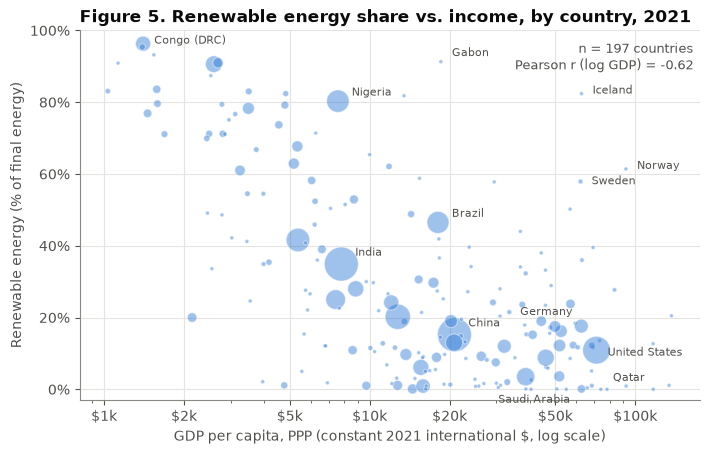

In [10]:
x = d[["gdp", "ren", "pop"]].dropna()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(x["gdp"], x["ren"], s=np.clip(x["pop"]/1e6*1.2, 8, 600), color=BLUE, alpha=0.45, edgecolor="white", lw=0.8)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(usd); ax.set_xticks([1000, 2000, 5000, 10000, 20000, 50000, 100000])
ax.yaxis.set_major_formatter(pct); ax.set_ylim(-3, 100)

LABELS = {"COD": (8, 0), "ISL": (8, 0), "NOR": (8, 0), "SWE": (8, -2), "QAT": (-6, 6), "SAU": (-8, -10),
          "USA": (8, -4), "CHN": (10, 6), "IND": (10, 6), "BRA": (10, 4), "GAB": (8, 4), "NGA": (10, 4), "DEU": (-6, 8)}
for c, (dx, dy) in LABELS.items():
    if c in x.index:
        ax.annotate(short(c), (x.at[c, "gdp"], x.at[c, "ren"]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8, color=TXT2, ha="left" if dx > 0 else "right")
r = np.corrcoef(np.log10(x["gdp"]), x["ren"])[0, 1]
ax.text(0.99, 0.97, f"n = {len(x)} countries\nPearson r (log GDP) = {r:.2f}", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color=TXT2)
ax.set_title(f"Figure 5. Renewable energy share vs. income, by country, {YEAR}")
ax.set_xlabel("GDP per capita, PPP (constant 2021 international $, log scale)")
ax.set_ylabel("Renewable energy (% of final energy)")
save(fig, "f5_scatter_total.png")

### Iteration 4: Reframing to modern renewables over time (Figure 6)
Separate *modern* renewables (non-hydro electricity: wind, solar, geothermal, etc.) from the biomass-heavy total.
Negative values in the low- and lower-middle-income lines are left visible, because they come from the data (see the anomaly check in Section 3).

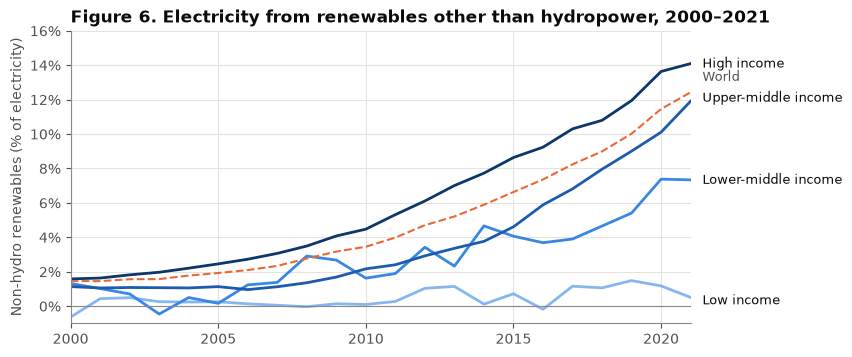

In [11]:
yrs = [str(y) for y in range(2000, int(YEAR) + 1)]
fig, ax = plt.subplots(figsize=(8, 3.8))
OFFSET = {"LIC": -0.2, "LMC": 0, "UMC": 0.2, "HIC": 0}       # nudge end labels apart
for g in GROUPS:
    s = series("EG.ELC.RNWX.ZS", g)[yrs]
    ax.plot([int(y) for y in yrs], s.values, color=RAMP[g], lw=2)
    ax.text(int(YEAR) + 0.4, s[YEAR] + OFFSET[g], NAMES[g], va="center", fontsize=9, color=TXT)
s = series("EG.ELC.RNWX.ZS", "WLD")[yrs]
ax.plot([int(y) for y in yrs], s.values, color=ORANGE, lw=1.5, ls="--")
ax.text(int(YEAR) + 0.4, s[YEAR] + 0.9, "World", va="center", fontsize=9, color=TXT2)
ax.yaxis.set_major_formatter(pct); ax.set_xlim(2000, int(YEAR)); ax.set_ylim(-1, 16)
ax.set_xticks(range(2000, int(YEAR) + 1, 5)); ax.axhline(0, color=MUTED, lw=0.8)
ax.set_title(f"Figure 6. Electricity from renewables other than hydropower, 2000–{YEAR}")
ax.set_ylabel("Non-hydro renewables (% of electricity)")
save(fig, "f6_ts_nonhydro.png")

## 6. Final visualization (Figure 7)
Small multiples with a shared log x-axis: **(A)** combustible renewables & waste (biomass proxy) vs. **(B)** non-hydro renewable electricity (wind/solar proxy).
Blue dots are countries. The dark line with orange markers joins the medians within income bands (the table in Section 4). Negative values are clipped to 0.
The two measures are shown side by side rather than stacked or summed, because they have different denominators (total energy use vs. electricity output).

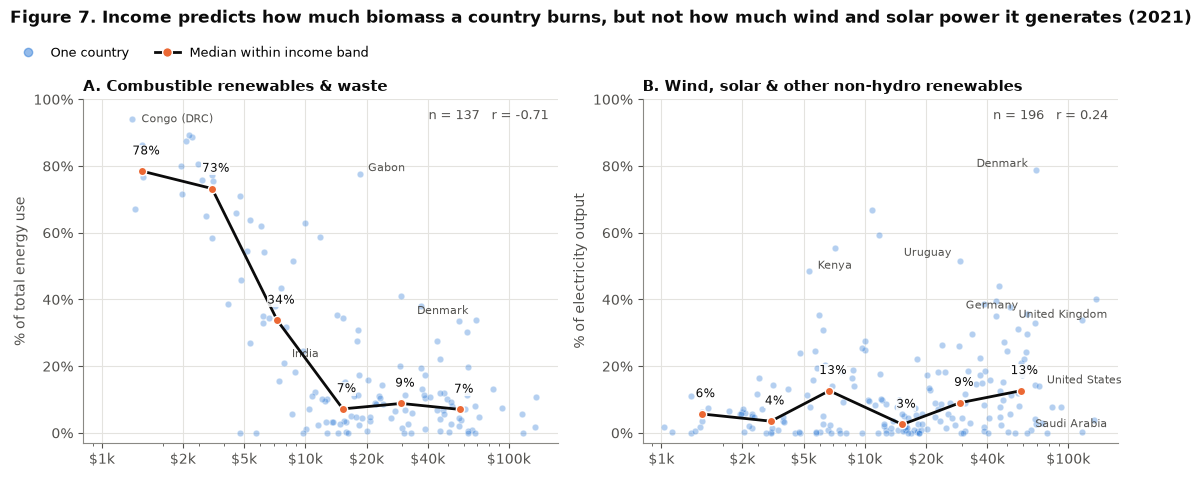

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 5.0), sharex=True)
PANELS = [("crnw", "A. Combustible renewables & waste", "% of total energy use"),
          ("rnwx", "B. Wind, solar & other non-hydro renewables", "% of electricity output")]
for ax, (k, title, ylab) in zip(axs, PANELS):
    x = d[["gdp", k]].dropna().copy(); x[k] = x[k].clip(lower=0)
    ax.scatter(x["gdp"], x[k], s=22, color=BLUE, alpha=0.35, edgecolor="white", lw=0.6)
    m = band_medians(k)
    ax.plot(m["gdp_median"], m["value_median"], color=TXT, lw=2, marker="o", ms=6,
            markerfacecolor=ORANGE, markeredgecolor="white", zorder=5)
    for gx, vv in zip(m["gdp_median"], m["value_median"]):
        ax.text(gx * 1.04, vv + 5, f"{vv:.0f}%", ha="center", fontsize=8.5, color=TXT, zorder=6,
                bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.85))
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(usd); ax.set_xticks([1000, 2500, 5000, 10000, 20000, 40000, 100000])
    ax.yaxis.set_major_formatter(pct); ax.set_ylim(-3, 100); ax.set_title(title, fontsize=11); ax.set_ylabel(ylab)
    rr = np.corrcoef(np.log10(x["gdp"]), x[k])[0, 1]
    ax.text(0.98, 0.97, f"n = {len(x)}   r = {rr:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=9, color=TXT2)

def label(ax, col, items):
    for c, (dx, dy) in items.items():
        if c in d.index and pd.notna(d.at[c, col]):
            ax.annotate(short(c), (d.at[c, "gdp"], max(d.at[c, col], 0)), xytext=(dx, dy), textcoords="offset points",
                        fontsize=8, color=TXT2, ha="left" if dx > 0 else "right")
label(axs[0], "crnw", {"COD": (7, -2), "IND": (6, 4), "DNK": (-6, 4), "GAB": (6, 2)})
label(axs[1], "rnwx", {"DNK": (-6, 2), "DEU": (-6, 4), "GBR": (6, -8), "USA": (6, 2), "KEN": (6, 2), "URY": (-6, 4), "SAU": (6, 4)})

fig.suptitle(f"Figure 7. Income predicts how much biomass a country burns, but not how much wind and solar power it generates ({YEAR})",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=TXT, y=0.975)
handles = [Line2D([], [], ls="", marker="o", color=BLUE, alpha=0.5, ms=6, label="One country"),
           Line2D([], [], color=TXT, lw=2, marker="o", markerfacecolor=ORANGE, markeredgecolor="white", ms=7,
                  label="Median within income band")]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 0.925), ncol=2, fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
save(fig, "f7_final.png")

## Notes for modifying the notebook
- **Different year:** change `YEAR` in Setup (renewable indicators end in 2021).
- **Different indicators:** edit `INDICATORS`; search for codes with
  `df[df['Indicator Name'].str.contains('keyword', case=False)][['Indicator Code','Indicator Name']].drop_duplicates()`.
- **Different income bands:** edit `BINS`.
- **Label other countries:** edit the `LABELS` dict (Figure 5) or the `label(...)` calls (Figure 7). Keys are ISO3 codes; values are text offsets in points.
- **Figure numbers:** if the write-up is renumbered, update the figure titles and the `save(...)` filenames together.